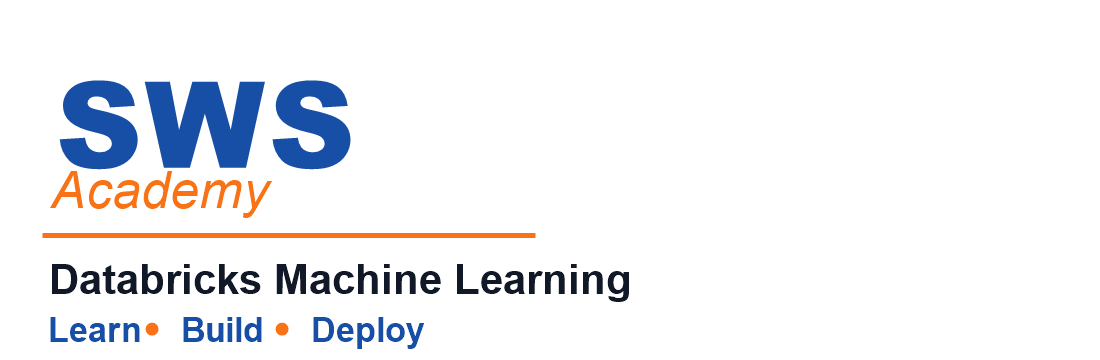


# Hyperparameter Tuning with Optuna

In this hands-on demo, you will learn how to leverage **Optuna**, a powerful optimization library, for efficient model tuning. We'll guide you through the process of performing **hyperparameter optimization**, demonstrating how to define the search space, objective function, and algorithm selection. Throughout the demo, you will utilize *MLflow* to seamlessly track the model tuning process, capturing essential information such as hyperparameters, metrics, and intermediate results. By the end of the session, you will not only grasp the principles of hyperparameter optimization but also be proficient in finding the best-tuned model using various methods such as the **MLflow API** and **MLflow UI**.

By integrating Optuna and MLflow, you can efficiently optimize hyperparameters and maintain comprehensive records of your machine learning experiments, facilitating reproducibility and collaborative research.

**Learning Objectives:**

*By the end of this demo, you will be able to:*

- Perform hyperparameter optimization using Optuna.
- Track the model tuning process with MLflow.
- Query previous runs from an experiment using the `MLflowClient`.
- Review an MLflow Experiment for visualizing results and selecting the best run.
- Read in the best model, make a prediction, and register the model to Unity Catalog. 



## REQUIRED - SELECT A COMPUTE ENVIRONMENT

<div style="border-left: 4px solid #F44336; background: #FFEBEE; padding: 16px 20px; border-radius: 4px; margin: 16px 0;">
<div style="display: flex; align-items: flex-start; gap: 12px;">
<div>
<strong style="color: #C62828; font-size: 1.1em;">Select Compute</strong>
<p style="margin: 8px 0 0 0; color: #333;">Before starting this notebook, select the required compute environment listed below.</p>
<ul style="margin: 12px 0 0 16px; color: #333;">
<li><strong>Serverless Compute, Version 5</strong> — <a href="https://docs.databricks.com/aws/en/compute/serverless/dependencies#-select-an-environment-version" style="color: #1976D2; text-decoration: underline;">How to select an environment version</a></li>
</ul>
<p style="margin: 8px 0 0 0; color: #333;"><strong>NOTE:</strong> This notebook was <strong>developed and tested using Serverless V5</strong>. Other compute options may work but are not guaranteed to behave the same or support all features demonstrated.</p>
</div>
</div>
</div>

<div style="width: 100%; font-family: sans-serif;"><div style="background: #F9F7F4; border-radius: 10px; padding: 24px 28px; box-shadow: 0 2px 8px rgba(27,49,57,0.06); border-top: 6px solid #FF5F46;">  <img src="../Includes/images/genie-code.png" style="height: 64px; margin-bottom: 10px;">  <div style="font-size: 15pt; color: #0B2026; line-height: 1.7; margin-bottom: 16px;">    Want to know more about hyperparameter tuning and Optuna in Databricks? Ask Genie Code. Click on the genie icon <img src="../Includes/images/genie-icon.png" style="height: 32px; vertical-align: middle;"> and begin querying. For example, click the <strong>Copy</strong> button below and paste into <strong>Genie Code</strong>.  </div>  <div style="display: flex; align-items: center; gap: 10px; background: #fff; border: 1px solid #ddd; border-radius: 6px; padding: 10px 14px; font-size: 14pt; font-family: monospace; color: #0B2026;">    <span id="genie-query-2-1" style="flex: 1;">What is Optuna and how does it perform hyperparameter optimization? What is the difference between grid search, random search, and Bayesian optimization, and when should I use each strategy for tuning a machine learning model?</span>    <button onclick="      var text = document.getElementById('genie-query-2-1').innerText;      var ta = document.createElement('textarea');      ta.value = text;      ta.style.position = 'fixed';      ta.style.opacity = '0';      document.body.appendChild(ta);      ta.select();      document.execCommand('copy');      document.body.removeChild(ta);      this.innerText = 'Copied!';      var btn = this;      setTimeout(function(){ btn.innerText = 'Copy'; }, 2000);    " style="background: #FF5F46; color: white; border: none; border-radius: 4px; padding: 4px 12px; font-size: 13pt; cursor: pointer; white-space: nowrap;">Copy</button>  </div></div></div>

### Classroom Setup

Run the following cell to configure your working environment for this course.

This setup will:
- Initialize the `SA` object (SWSAcademy helper)
- Configure your **default catalog** and **schema**
- Provision any supporting configuration needed for this demo

**NOTE:** The `SA` object is only available in SWSAcademy courses.

In [ ]:
%pip install -U -qq optuna
dbutils.library.restartPython()

In [ ]:
%run ../Includes/Classroom-Setup-2.1

**Other Conventions:**

Throughout this demo, we'll refer to the object `SA`. This object, provided by SWSAcademy, contains variables such as your username, catalog name, schema name, working directory, and dataset locations. Run the code block below to view these details:

In [ ]:
print(f"Username:          {SA.username}")
print(f"Catalog Name:      {SA.catalog_name}")
print(f"Schema Name:       {SA.schema_name}")
print(f"Working Directory: {SA.paths.working_dir}")
print(f"Dataset Location:  {SA.paths.datasets}")

## Prepare Dataset

Before we start fitting a model, we need to prepare dataset. First, we will load dataset, then we will split it to train and test sets.

### Load Dataset

In this demo we will be using the CDC Diabetes dataset from the Databricks Marketplace. This dataset has been read in and written to a feature table called `diabetes` in our working schema.

In [ ]:
# load data from the feature table
table_name = f"{SA.catalog_name}.{SA.schema_name}.diabetes"
diabetes_dataset = spark.read.table(table_name)
diabetes_pd = diabetes_dataset.drop('unique_id').toPandas()

# review dataset and schema
display(diabetes_pd)
print(diabetes_pd.info())


### Train/Test Split

Next, we will divide the dataset to training and testing sets.

In [ ]:
from sklearn.model_selection import train_test_split

print(f"We have {diabetes_pd.shape[0]} records in our source dataset")

# split target variable into it's own dataset
target_col = "Diabetes_binary"
X_all = diabetes_pd.drop(labels=target_col, axis=1)
y_all = diabetes_pd[target_col]

# test / train split
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, train_size=0.95, random_state=42)

y_train = y_train.astype(float)
y_test = y_test.astype(float)

print(f"We have {X_train.shape[0]} records in our training dataset")
print(f"We have {X_test.shape[0]} records in our test dataset")

## Hyperparameter Tuning

### Define the Objective Function

An objective function in Optuna is a Python function that defines the optimization target. It takes a single argument, typically named trial, which is an instance of the optuna.Trial class. This function is responsible for:

1. Defining the hyperparameter search space

1. Training the model with the suggested hyperparameters

1. Evaluating the model's performance

1. Returning a scalar value that Optuna will try to optimize (minimize or maximize)

In our case, we are working with scikit-learn's `DecisionTreeClassifier`. Start by defining the search space for the model. Our hyperparameters are:
- `criterion`: chooses between `gini` and `entropy`. Defining the criterion parameter allows the algorithm to try both options during tuning and can assist in identifying which criterion works best. [TPE](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html#optuna.samplers.TPESampler) is the [default](https://optuna.readthedocs.io/en/stable/tutorial/10_key_features/003_efficient_optimization_algorithms.html#pruning), though there are [other sampling methods](https://optuna.readthedocs.io/en/stable/reference/samplers/index.html) like GPSampler and BruteForceSampler.
- `max_depth`: an integer between 5 and 50
- `min_samples_split`: an integer between 2 and 40
- `min_samples_leaf`: an integer between 1 and 20

The objective function will also have a nested MLflow runs for logging each trial start a new MLflow run for each trial using `with mlflow.start_run()`. We will also manually log metrics and the scikit-learn model within the objective function. Note that the training process is using cross-validation (5-fold CV in fact) and returns the negative mean of the fold results. 


>   - _**Gini impurity** measures how often a randomly chosen sample would be incorrectly classified if randomly labeled according to the current class distribution. It quantifies the probability of misclassification._
>  - _**Entropy** measures the amount of uncertainty or disorder in the dataset. It quantifies how “impure” a node is in terms of class distribution, with higher entropy meaning more disorder (i.e., more uncertainty in classification)._

In [ ]:
import optuna
import mlflow
import mlflow.sklearn
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
from mlflow.models.signature import infer_signature
import time

# Every trial uploads a model, so retry the occasional transient storage error
# instead of failing the whole study.
def log_model_with_retry(model, name, retries=3, **kwargs):
    for attempt in range(1, retries + 1):
        try:
            return mlflow.sklearn.log_model(model, name, **kwargs)
        except mlflow.exceptions.MlflowException as e:
            if attempt == retries:
                raise
            print(f"Model upload failed (attempt {attempt}/{retries}), retrying: {str(e)[:120]}")
            time.sleep(5 * attempt)

# Define the objective function
def optuna_objective_function(trial):
    # Define hyperparameter search space
    params = {
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'max_depth': trial.suggest_int('max_depth', 5, 50),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 40),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20)
    }
    
    # Start an MLflow run for logging
    with mlflow.start_run(nested=True, run_name=f"Model Tuning with Optuna - Trial {trial.number}"):

        # Log parameters with MLflow
        mlflow.log_params(params)

        dtc = DecisionTreeClassifier(**params)
        scoring_metrics = ['accuracy', 'precision', 'recall', 'f1']
        cv_results = cross_validate(dtc, X_train, y_train, cv=5, scoring=scoring_metrics, return_estimator=True)
        
        # Log cross-validation metrics to MLflow
        for metric in scoring_metrics:
            mlflow.log_metric(f'cv_{metric}', cv_results[f'test_{metric}'].mean())

        # Train the model on the full training set
        final_model = DecisionTreeClassifier(**params)
        final_model.fit(X_train, y_train)

        # Create input signature using the first row of X_train
        input_example = X_train.iloc[[0]]
        signature = infer_signature(input_example, final_model.predict(input_example))

        # Log the model with input signature
        log_model_with_retry(final_model, "decision_tree_model", signature=signature, input_example=input_example)

        # Compute the mean from cross-validation
        f1_score_mean = cv_results['test_f1'].mean()

        # Metric to be minimized
        return -f1_score_mean

### Optimize the Scikit-Learn Model on Single-Machine Optuna and Log Results with MLflow

Before running the optimization, we need to perform two key steps:

1. **Initialize an Optuna Study** using `optuna.create_study()`.  
   - A *study* represents an optimization process consisting of multiple trials.  
   - A *trial* is a single execution of the *objective function* with a specific set of hyperparameters.  

2. **Run the Optimization** using `study.optimize()`.  
   - This tells Optuna how many trials to perform and allows it to explore the search space.  

Each trial will be logged to MLflow, including the hyperparameters tested and their corresponding cross-validation results. Optuna will handle the optimization while training continues.

#### **Steps:**
- **Set up an Optuna study** with `optuna.create_study()`. 
- **Start an MLflow run** with `mlflow.start_run()` to log experiments. 
- **Optimize hyperparameters** using `study.optimize()` within the MLflow context.

> **Note on `n_jobs` in `study.optimize()`:**  
> The `n_jobs` argument controls the **number of trials running in parallel** using multi-threading **on a single machine**.  
> - If `n_jobs=-1`, Optuna will use **all available CPU cores** (e.g., on a 4-core machine, it will likely use all 4 cores).  
> - If `n_jobs` is **undefined (default)**, trials run **sequentially (single-threaded)**.  
> - **Important:** `n_jobs` does **not** distribute trials across multiple nodes in a Spark cluster. To parallelize across nodes, use `SparkTrials()` instead.

> **Why We Don't Use `MLflowCallback`:**  
> Optuna provides an [`MLflowCallback`](https://optuna.readthedocs.io/en/v2.0.0/reference/generated/optuna.integration.MLflowCallback.html) for automatic logging. However, in this demo, we are demonstrating how to integrate the MLflow API with Optuna separate from `MLflowCallback`.

First, we will delete all previous runs to keep our workspace and experiment tidy.

In [ ]:
# Set the MLflow experiment name and get the id
experiment_name = f"/Users/{SA.username}/Hyperparameter_Tuning_with_Optuna_{SA.schema_name}"
print(f"Experiment Name: {experiment_name}")
mlflow.set_experiment(experiment_name)
experiment_id = mlflow.get_experiment_by_name(experiment_name).experiment_id
print(f"Experiment ID: {experiment_id}")

print("Clearing out old runs (If you want to add more runs, change the n_trial parameter in the next cell) ...")
# Get all runs
runs = mlflow.search_runs(experiment_ids=[experiment_id], output_format="pandas")

if runs.empty:
    print("No runs found in the experiment.")
else:
    # Iterate and delete each run
    for run_id in runs["run_id"]:
        mlflow.delete_run(run_id)
        print(f"Deleted run: {run_id}")

    print("All runs have been deleted.")

In [ ]:
study = optuna.create_study(
    study_name="optuna_hpo",
    direction="minimize"
)

with mlflow.start_run(run_name='demo_optuna_hpo') as parent_run:
    # Run optimization
    study.optimize(
        optuna_objective_function, 
        n_trials=10
        )

---
## Comparing Sampling Strategies: Grid Search and Random Search

Optuna's default sampler is **TPE (Tree-structured Parzen Estimator)**, a Bayesian method that
learns from past trials to focus on promising regions. Optuna also supports two classical
strategies via built-in samplers:

| Sampler | Strategy | Best for |
|---|---|---|
| `TPESampler` *(default)* | Bayesian (model-based) | Large search spaces, continuous params |
| `GridSampler` | Exhaustive grid — tries every combination | Small discrete search spaces |
| `RandomSampler` | Uniform random draw | Baselines, fast exploration |

The next two cells run short studies using each sampler so you can compare their trial histories
in the Optuna visualizations.

### Grid Search with `GridSampler`

`GridSampler` requires an explicit dictionary of candidate values for every parameter.
Optuna iterates through all combinations in the Cartesian product — identical to sklearn's
`GridSearchCV` — but still logs each trial to MLflow automatically.

The grid below uses two candidate values per parameter (2×2×2×2 = **16 combinations**) to keep
the classroom run short. Notice how quickly the count grows: adding just one more value to
each of the last three parameters makes it 2×3×3×3 = 54 trials — this is why exhaustive grid
search gets expensive and random/TPE sampling is usually preferred for larger search spaces.

In [ ]:
import optuna
from optuna.samplers import GridSampler

grid_search_space = {
    "criterion":         ["gini", "entropy"],
    "max_depth":         [5, 20],
    "min_samples_split": [2, 20],
    "min_samples_leaf":  [1, 10],
}

grid_sampler = GridSampler(grid_search_space)

grid_study = optuna.create_study(
    study_name="optuna_grid_search",
    direction="minimize",
    sampler=grid_sampler,
)

with mlflow.start_run(run_name="demo_optuna_grid_search") as grid_run:
    grid_study.optimize(optuna_objective_function, n_trials=16)  # 2×2×2×2 = 16 combos

print(f"Grid search — best params : {grid_study.best_params}")
print(f"Grid search — best value  : {grid_study.best_value:.4f}")

### Random Search with `RandomSampler`

`RandomSampler` draws hyperparameter values uniformly at random from the same search space
defined in the objective function. It serves as a strong baseline: when random search matches
or beats TPE on small trial budgets, it signals the search space may be relatively flat.

In [ ]:
from optuna.samplers import RandomSampler

random_sampler = RandomSampler(seed=42)

random_study = optuna.create_study(
    study_name="optuna_random_search",
    direction="minimize",
    sampler=random_sampler,
)

with mlflow.start_run(run_name="demo_optuna_random_search") as random_run:
    random_study.optimize(optuna_objective_function, n_trials=10)

print(f"Random search — best params : {random_study.best_params}")
print(f"Random search — best value  : {random_study.best_value:.4f}")

### Compare Sampler Results

The cell below summarises the best negative-F1 value achieved by each of the three
strategies in this demo so you can quickly gauge their relative performance.

In [ ]:
results = {
    "TPE (default)": study.best_value,
    "Grid Search":   grid_study.best_value,
    "Random Search": random_study.best_value,
}

print("Sampler Comparison — Best Negative CV F1")
print("-" * 45)
for sampler_name, best_val in results.items():
    print(f"  {sampler_name:<20} {best_val:.4f}")

## Review Tuning Results

We can use the MLflow API to review the trial results.

In [ ]:
import mlflow
import pandas as pd

# Define your experiment name or ID
experiment_id = parent_run.info.experiment_id # Replace with your actual experiment ID

# Fetch all runs from the experiment
df_runs = mlflow.search_runs(
  experiment_ids=[experiment_id]
  )

df_runs = df_runs[df_runs['tags.mlflow.runName'] != 'demo_optuna_hpo']

display(df_runs)

We can use the Optuna study to get the best parameters and F1-score. Validate this agrees with the table results from the previous cell's output.

In [ ]:
# Display the best hyperparameters and metric
print(f"Best hyperparameters: {study.best_params}")
print(f"Best negative-F1 score: {study.best_value}")

## Find the Best Run Based on F1-Score

In this section, we will search for registered models. There are couple of ways to achieve this. We will show how to search runs using MLflow API and the UI.

**The output links for using Optuna gave the best runs. Why can't we just use that?**

You totally can! But this is the same as using the UI to navigate to the trial that was the best (which is shown below).

### Option 1: Find the Best Run - MLFlow API

Using the MLFlow API, you can search runs in an experiment, which returns results into a Pandas DataFrame.

In [ ]:
experiment_id = parent_run.info.experiment_id
print(f"Experiment ID: {experiment_id}")

In [ ]:
from mlflow.entities import ViewType

search_runs_pd = mlflow.search_runs(
    experiment_ids=[experiment_id],
    order_by=["metrics.cv_f1 DESC"],
    max_results=1
)

display(search_runs_pd)

In [ ]:
from mlflow.entities import ViewType

search_runs_pd = mlflow.search_runs(
    experiment_ids=[experiment_id],
    order_by=["metrics.cv_f1 ASC"],
    max_results=1
)

display(search_runs_pd)

### Option 2 - Find the Best Run - MLflow UI

The simplest way of seeing the tuning result is to use MLflow UI. 

1. Click on **Experiments** from left menu.

1. Select experiment which has the same name as this notebook's title (**`Hyperparameter_Tuning_with_Optuna_{schema_name}`**).

1. Click on the graph icon at the top left under **Runs**.

1. Click on the parent run or manually select all 10 runs to compare. The graphs on the right of the screen will appear for inspection.

# Visualize the Hyperparameters 

By now, we have determined which trial had the best run according to the f1-score. Now, let's visually inspect our other search space elements with respect to this metric.

In [ ]:
import matplotlib.pyplot as plt


# Ensure the necessary parameters exist in the DataFrame before plotting
required_params = ["params.min_samples_leaf", "params.max_depth", "params.min_samples_split", "metrics.cv_f1", "tags.mlflow.runName"]
df_filtered = df_runs.dropna(subset=required_params, how="any")

# Convert parameters to appropriate types
df_filtered["params.min_samples_split"] = df_filtered["params.min_samples_split"].astype(float)
df_filtered["params.max_depth"] = df_filtered["params.max_depth"].astype(float)
df_filtered["metrics.cv_f1"] = df_filtered["metrics.cv_f1"].astype(float)

# Identify the best run index (assuming higher f1 is better)
best_run_index = df_filtered["metrics.cv_f1"].idxmax()
best_run_name = df_filtered.loc[best_run_index, "tags.mlflow.runName"]

# Extract run names for x-axis labels
run_names = df_filtered["tags.mlflow.runName"]

# Create a figure and axis for bar chart
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar chart for min_samples_split and max_depth
df_filtered[["params.min_samples_split", "params.max_depth"]].plot(kind="bar", ax=ax1, edgecolor="black")

ax1.set_xlabel("Run Name")
ax1.set_ylabel("Parameter Values")
ax1.set_title("Hyperparameters & cv_f1 Score per Run")
ax1.legend(["Max Features", "Max Depth"])
ax1.set_xticks(range(len(df_filtered)))
ax1.set_xticklabels(run_names, rotation=45, ha="right")  # Rotate for readability

# Create a second y-axis for the cv_f1 score line chart
ax2 = ax1.twinx()
ax2.plot(
    range(len(df_filtered)),  # X-axis indices
    df_filtered["metrics.cv_f1"],
    marker="o",
    linestyle="-",
    color="blue",
    label="cv_f1 Score"
)

# Highlight the best run with a bold marker
ax2.plot(
    df_filtered.index.get_loc(best_run_index),  # Get positional index
    df_filtered.loc[best_run_index, "metrics.cv_f1"],
    marker="o",
    markersize=10,
    color="red",
    label="Best Run"
)

# Add a vertical dashed line to indicate the best run
ax2.axvline(df_filtered.index.get_loc(best_run_index), color="red", linestyle="--")

ax2.set_ylabel("cv_f1 Score")

# Add legend
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
plt.show()

# Pie chart for criterion
plt.figure(figsize=(8, 8))
df_filtered["params.criterion"].value_counts().plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Criterion Distribution")
plt.ylabel("")  # Hide y-label for better visualization
plt.show()

## Load the Best Model and Parameters
To load the model and make a prediction, let's use the information from Option 2 shown above. Run the next cell to get the value.


### Copy and Paste Option
Alternatively, you can set the variables shown below manually. Using either the output from Option 1 or Option 2 or the UI from Option 3, locate the `run_id` and the `experiment_id`. With Option 1 or 2, this is simply the value in the first two columns. In the UI, this is presented to you in the Details table when clicking on the specific run.

In [ ]:
#convert search_runs_pd to pyspark dataframe
search_runs_sd = spark.createDataFrame(search_runs_pd)


# Get the string value from run_id and experiment_id from PySpark DataFrame hpo_runs_df
run_id = search_runs_sd.select("run_id").collect()[0][0]
experiment_id = search_runs_sd.select("experiment_id").collect()[0][0]

print(f"Run ID: {run_id}")
print(f"Experiment ID: {experiment_id}")

In [ ]:
import mlflow
import json

# Grab an input example from the test set (pandas DataFrame)
input_example = X_test.iloc[[0]]

# (works regardless of whether artifacts are stored on DBFS/S3/UC-managed storage)
model_uri = f"runs:/{run_id}/decision_tree_model"

# Load the model using the run URI
loaded_model = mlflow.pyfunc.load_model(model_uri)

# Retrieve model parameters
client = mlflow.tracking.MlflowClient()
params = client.get_run(run_id).data.params

# Display model parameters
print("Best Model Parameters:")
print(json.dumps(params, indent=4))

# (Optional) sanity check: run a prediction
pred = loaded_model.predict(input_example)
print("Prediction:", pred)

### Make a Prediction

In [ ]:
# Make a prediction
test_prediction = loaded_model.predict(input_example)
# X_test is a pandas dataframe - let's add the test_prediction output as a new column
input_example['prediction'] = test_prediction
display(input_example)

### Register the Model to Unity Catalog

After running the following cell, navigate to our working catalog and schema (see course setup above) and validate the model has been registered.

In [ ]:
mlflow.set_registry_uri("databricks-uc")
model_uri = f'runs:/{run_id}/decision_tree_model'
mlflow.register_model(model_uri=model_uri, name=f"{SA.catalog_name}.{SA.schema_name}.demo_optuna_model")


## Conclusion

In this demo, we've explored how to enhance your model's performance using **Optuna** for hyperparameter optimization and **MLflow** for tracking the tuning process. By employing Optuna's efficient search algorithms, you've learned to fine-tune your model's parameters effectively. Simultaneously, MLflow has facilitated seamless monitoring and logging of each trial, capturing essential information such as hyperparameters, metrics, and intermediate results. Additionally, you learned how to register the best model within Unity Catalog. Moving forward, integrating these tools into your workflow will be instrumental in improving your model's performance and simplifying the fine-tuning process.

<div style="border-top: 1px solid #E5E7EB; margin-top: 32px; padding: 12px 0; color: #4B5563; font-size: 13px; font-family: Arial, Helvetica, sans-serif; line-height: 1.5;">
  <div><strong>SWS Academy</strong> &nbsp;|&nbsp; Databricks AI &amp; Machine Learning Course</div>
  <div>&copy; 2026 SWS Academy. All rights reserved. Unauthorized reproduction or distribution is prohibited.</div>
</div>